[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amiguelartiaga-docencia/2627_mlcom_tp2/blob/main/notebooks/ejemplo3_biometria.ipynb)

# Ejemplo 3 — Verificación facial con ArcFace

Comparamos la imagen de enrolamiento de una identidad con una cara concreta de una foto, dada por su caja. El score es el producto escalar de los dos embeddings ArcFace normalizados (similitud coseno).

- Pareja 1: enrolamiento de Lucía Nogueira frente a la cara A → **target** (misma persona).
- Pareja 2: enrolamiento de Lucía Nogueira frente a la cara B → **non target** (otra persona).

## Instalación y datos (Colab)

La celda siguiente instala los paquetes y clona el repositorio de la práctica (con las imágenes) en `/content`, así que el cuaderno funciona aunque se suba suelto a Colab.

In [ ]:
!pip install insightface onnxruntime
!git clone https://github.com/amiguelartiaga-docencia/2627_mlcom_tp2.git
%cd /content/2627_mlcom_tp2

## Modelos: detector RetinaFace + reconocimiento ArcFace

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from insightface.app import FaceAnalysis

app = FaceAnalysis(name='buffalo_l', allowed_modules=['detection', 'recognition'])
app.prepare(ctx_id=-1, det_size=(640, 640))

## Enrolamiento, foto y las dos cajas

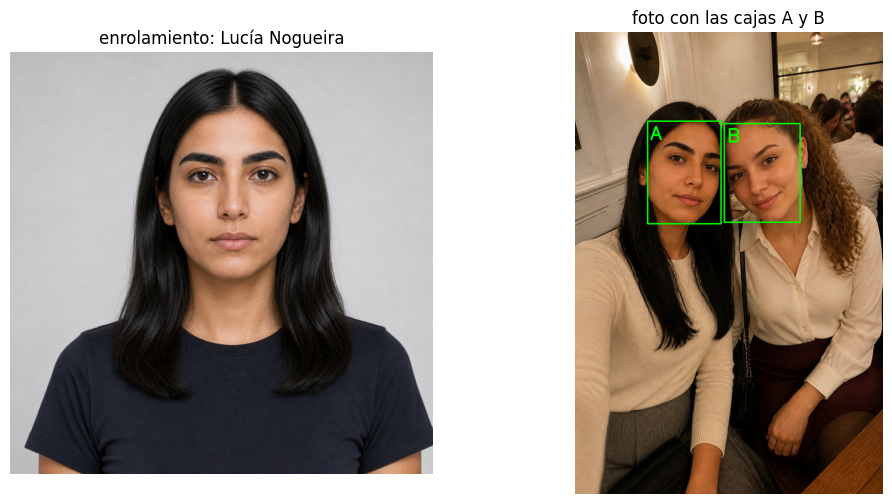

In [3]:
enrol = cv2.imread('img/identidades/lucia_nogueira.jpg')
foto = cv2.imread('img/fotos/img_78ed00c02760.jpg')

caja_A = [241, 296, 485, 637]
caja_B = [496, 304, 748, 632]

ver = foto.copy()
for nombre, (x1, y1, x2, y2) in [('A', caja_A), ('B', caja_B)]:
    cv2.rectangle(ver, (x1, y1), (x2, y2), (0, 255, 0), 4)
    cv2.putText(ver, nombre, (x1 + 10, y1 + 60), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 255, 0), 5)

plt.figure(figsize=(12, 6))
for k, (img, titulo) in enumerate([(enrol, 'enrolamiento: Lucía Nogueira'), (ver, 'foto con las cajas A y B')]):
    plt.subplot(1, 2, k + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
plt.show()

## Embeddings

Recortamos cada caja con un pequeño margen y volvemos a pasar el detector sobre el recorte (si aparece un trozo de otra cara nos quedamos con la más grande): insightface alinea la cara con sus 5 puntos faciales, la lleva a 112×112 y calcula el embedding ArcFace (512 valores, ya normalizado).

In [4]:
def recorte(img, caja, margen=0.2):
    x1, y1, x2, y2 = caja
    w, h = x2 - x1, y2 - y1
    return img[max(0, int(y1 - margen * h)):int(y2 + margen * h), max(0, int(x1 - margen * w)):int(x2 + margen * w)]

def embedding(img):
    caras = app.get(img)
    cara = max(caras, key=lambda c: (c.bbox[2] - c.bbox[0]) * (c.bbox[3] - c.bbox[1]))  # la más grande
    return cara.normed_embedding

cara_A = recorte(foto, caja_A)
cara_B = recorte(foto, caja_B)

e_enrol = embedding(enrol)
e_A = embedding(cara_A)
e_B = embedding(cara_B)
print(e_enrol.shape)

(512,)


## Scores

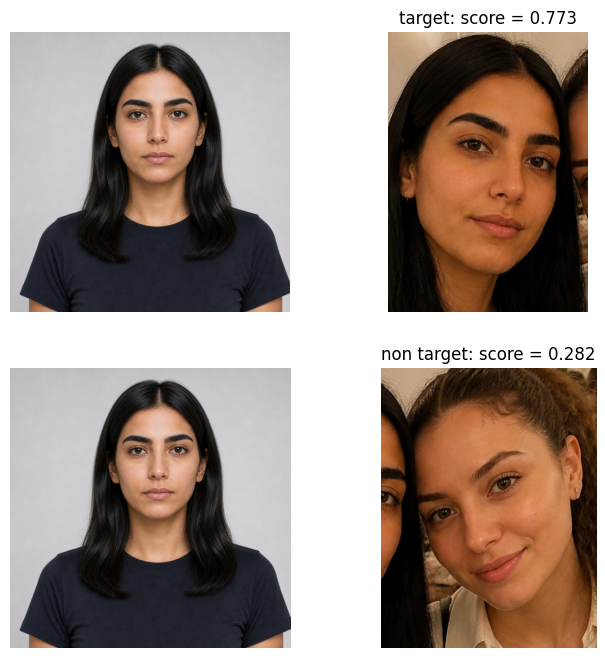

target     : 0.773
non target : 0.282


In [5]:
score_target = np.dot(e_enrol, e_A)
score_non_target = np.dot(e_enrol, e_B)

plt.figure(figsize=(8, 8))
for fila, (cara, score, tipo) in enumerate([(cara_A, score_target, 'target'), (cara_B, score_non_target, 'non target')]):
    plt.subplot(2, 2, 2 * fila + 1)
    plt.imshow(cv2.cvtColor(enrol, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.subplot(2, 2, 2 * fila + 2)
    plt.imshow(cv2.cvtColor(cara, cv2.COLOR_BGR2RGB))
    plt.title(f'{tipo}: score = {score:.3f}')
    plt.axis('off')
plt.show()

print(f'target     : {score_target:.3f}')
print(f'non target : {score_non_target:.3f}')